---
tags: [integration, optimization, variational]
---

# qBraid Support

This page introduces qBraid support in Qamomile and shows how to run a
Qamomile workflow with `QBraidDevice`. Qamomile connects to qBraid through
its Qiskit artifact format, so the usual flow is
`qkernel` → `Qiskit` target → `QBraidDevice`.

## What this notebook shows

This notebook is a qBraid tutorial built around the original MaxCut
workflow. The main goal is to configure the qBraid device, compile a qkernel
to one QPY artifact, reuse that artifact throughout the optimization loop,
and inspect the final samples returned by qBraid.

Documentation cannot submit remote work without user credentials. We execute
the complete eight-node, five-layer workflow with Qiskit Aer through a compiled
QPY artifact, then show the credential-dependent device
substitution. The workflow retains graph construction, continuous parameter
optimization, the final energy distribution, partition visualization, and
the SCIP comparison.

## Installation

```bash
pip install "qamomile[qbraid]" jijmodeling ommx-pyscipopt-adapter
```

In [1]:
# Install the latest Qamomile and its qBraid integration through pip!
# !pip install "qamomile[qbraid]" jijmodeling ommx-pyscipopt-adapter

In [2]:
import os
from collections import defaultdict

import jijmodeling as jm
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from ommx_pyscipopt_adapter import OMMXPySCIPOptAdapter
from scipy.optimize import minimize

from qamomile.optimization import BinaryModel, QAOAExperiment
from qamomile.persistence import deserialize, serialize
from qamomile.qiskit import Aer, load_circuit

docs_test_mode = os.environ.get("QAMOMILE_DOCS_TEST") == "1"
SEED = 901
rng = np.random.default_rng(SEED)

## Construct the MaxCut Problem

The original tutorial uses a reproducible eight-node 3-regular graph. For
spins $s_i\in\{-1,+1\}$, minimizing

$$
E(\mathbf{s})=\frac12\sum_{(i,j)\in E}s_i s_j-\frac{|E|}{2}
$$

is equivalent to maximizing the number of cut edges, with $E=-\mathrm{cut}$.

In [3]:
graph = nx.random_regular_graph(d=3, n=8, seed=SEED)
positions = nx.spring_layout(graph, seed=SEED)
EDGES = tuple(sorted(tuple(sorted(edge)) for edge in graph.edges()))

assert graph.number_of_nodes() == 8
assert graph.number_of_edges() == 12

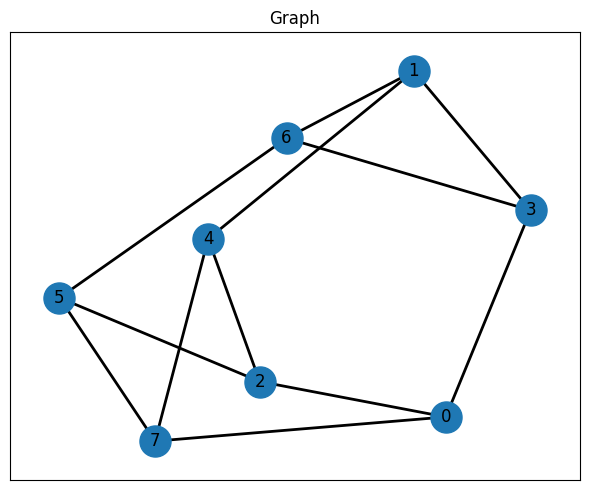

In [4]:
figure, axis = plt.subplots(figsize=(6, 5))
axis.set_title("Graph")
nx.draw_networkx(
    graph,
    positions,
    ax=axis,
    node_size=500,
    width=2,
    with_labels=True,
)
plt.tight_layout()
plt.show()

## Build and Compile Five-Layer QAOA

`QAOAExperiment` closes the spin Hamiltonian and five-layer topology into one
typed program. Only `gammas` and `betas` remain in the runtime ABI. The
Qiskit target emits deterministic QPY bytes; neither local Aer nor qBraid
changes the authored problem or ansatz. Each endpoint owns SDK preparation; compile against its target before launch.

In [5]:
model = BinaryModel.from_ising(
    {edge: 0.5 for edge in EDGES},
    constant=-len(EDGES) / 2.0,
    variables=range(graph.number_of_nodes()),
)
LAYERS = 5
experiment = QAOAExperiment(model, layers=LAYERS)
endpoint = Aer()
compiled = experiment.compile(to=endpoint.target)
restored_artifact = deserialize(serialize(compiled.artifact))
circuit = load_circuit(restored_artifact)

assert restored_artifact.execution_identity == compiled.artifact.execution_identity
assert circuit.num_qubits == graph.number_of_nodes()
assert circuit.num_parameters == 2 * LAYERS
assert tuple(slot.name for slot in compiled.artifact.parameter_abi.slots) == (
    "gammas",
    "betas",
)

print(circuit.draw(output="text", fold=120))

     ┌───────────────────────────────────────────────────────────────────────┐┌─┐                     
q_0: ┤0                                                                      ├┤M├─────────────────────
     │                                                                       │└╥┘┌─┐                  
q_1: ┤1                                                                      ├─╫─┤M├──────────────────
     │                                                                       │ ║ └╥┘┌─┐               
q_2: ┤2                                                                      ├─╫──╫─┤M├───────────────
     │                                                                       │ ║  ║ └╥┘┌─┐            
q_3: ┤3                                                                      ├─╫──╫──╫─┤M├────────────
     │  qamomile.optimization.qaoa.qaoa_state(p0,p1,p2,p3,p4,p5,p6,p7,p8,p9) │ ║  ║  ║ └╥┘┌─┐         
q_4: ┤4                                                                  

## Optimize the QAOA Parameters

The objective passes named `gammas` and `betas` to the compiled program
and samples it with the Aer endpoint. The adapter prepares the SDK circuit
and normalizes bit order; the Rust-owned model decodes and averages spin
energies. The remote example compiles the same experiment for its endpoint.

In [6]:
OPTIMIZATION_SHOTS = 16 if docs_test_mode else 2_000
MAX_ITERATIONS = 12 if docs_test_mode else 100
energy_history = []


def sample_coordinate(parameters, *, shots: int, seed: int):
    """Sample one aggregate QAOA coordinate and decode its spin energies."""

    record = compiled.run(
        on=endpoint,
        gammas=tuple(float(value) for value in parameters[:LAYERS]),
        betas=tuple(float(value) for value in parameters[LAYERS:]),
        shots=shots,
        seed=seed,
    )
    return record.samples


def objective_function(parameters) -> float:
    """Return and record the sampled mean MaxCut energy."""

    decoded = sample_coordinate(
        parameters,
        shots=OPTIMIZATION_SHOTS,
        seed=SEED + len(energy_history),
    )
    energy_history.append(decoded.mean_energy)
    return decoded.mean_energy


initial_parameters = rng.uniform(-np.pi / 4.0, np.pi / 4.0, 2 * LAYERS)
optimization = minimize(
    objective_function,
    initial_parameters,
    method="COBYLA",
    options={"maxiter": MAX_ITERATIONS, "rhobeg": 0.5},
)

print(f"Optimized gammas: {optimization.x[:LAYERS]}")
print(f"Optimized betas: {optimization.x[LAYERS:]}")
print(f"Final mean energy: {optimization.fun:+.4f}")

assert len(optimization.x) == 2 * LAYERS
assert len(energy_history) == optimization.nfev

Optimized gammas: [0.8442618  1.12951269 0.25883511 0.54783405 0.1339684 ]
Optimized betas: [-0.51932668  0.4618978  -0.73706664 -0.3264862  -0.5844266 ]
Final mean energy: -7.1735


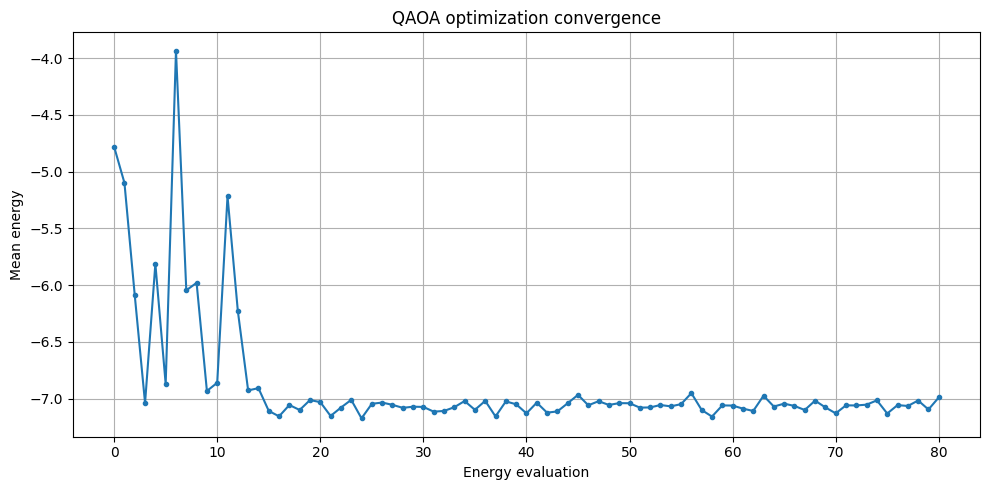

In [7]:
plt.figure(figsize=(10, 5))
plt.plot(energy_history, marker="o", markersize=3)
plt.xlabel("Energy evaluation")
plt.ylabel("Mean energy")
plt.title("QAOA optimization convergence")
plt.grid(True)
plt.tight_layout()
plt.show()

## Evaluate the Optimized Distribution

A final 2,000-shot run shows the full energy distribution and supplies the
lowest-energy observed partition.

In [8]:
FINAL_SHOTS = 128 if docs_test_mode else 2_000
final_samples = sample_coordinate(
    optimization.x,
    shots=FINAL_SHOTS,
    seed=2 * SEED,
)
energy_counts = defaultdict(int)
for sample in final_samples.samples:
    energy_counts[sample.energy] += sample.occurrences

best_sample = final_samples.lowest
best_spins = dict(best_sample.assignment)
best_cut = sum(best_spins[left] != best_spins[right] for left, right in EDGES)

print(f"Best QAOA energy: {best_sample.energy:+.1f}")
print(f"Best QAOA cut: {best_cut}")
print(f"Best QAOA spins: {best_spins}")

assert final_samples.total_occurrences == FINAL_SHOTS
assert best_sample.energy == -float(best_cut)

Best QAOA energy: -10.0
Best QAOA cut: 10
Best QAOA spins: {0: -1, 1: -1, 2: 1, 3: 1, 4: -1, 5: -1, 6: 1, 7: 1}


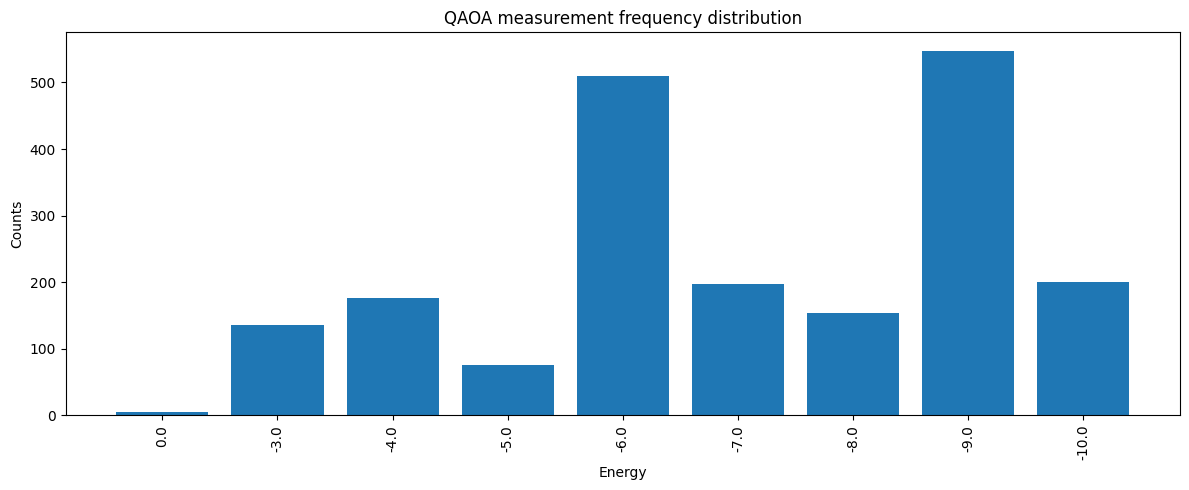

In [9]:
energies = sorted(energy_counts, reverse=True)
plt.figure(figsize=(12, 5))
plt.bar(
    np.arange(len(energies)),
    [energy_counts[energy] for energy in energies],
)
plt.xticks(np.arange(len(energies)), energies, rotation=90)
plt.xlabel("Energy")
plt.ylabel("Counts")
plt.title("QAOA measurement frequency distribution")
plt.tight_layout()
plt.show()

## Visualize the Best Solution

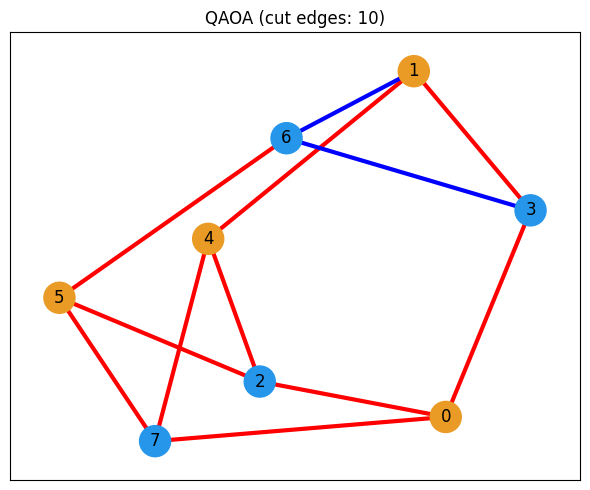

In [10]:
def show_solution(assignment, title: str) -> None:
    """Draw one binary or spin assignment on the MaxCut graph."""

    first_group = {node for node, value in assignment.items() if value in {1, 1.0}}
    edge_colors = [
        "r" if (left in first_group) != (right in first_group) else "b"
        for left, right in EDGES
    ]
    node_colors = [
        "#2696EB" if node in first_group else "#EA9B26" for node in graph.nodes()
    ]
    cut_edges = sum(color == "r" for color in edge_colors)
    _, axis = plt.subplots(figsize=(6, 5))
    axis.set_title(f"{title} (cut edges: {cut_edges})")
    nx.draw_networkx(
        graph,
        positions,
        ax=axis,
        node_size=500,
        width=3,
        with_labels=True,
        edge_color=edge_colors,
        node_color=node_colors,
    )
    plt.tight_layout()
    plt.show()


show_solution(best_spins, "QAOA")

## Run the Same Experiment on qBraid

Remote submission requires a qBraid account and creates external work, so the
documentation build does not execute it. The optimizer body can replace its
local endpoint with a `QBraidDevice` and compile for its target, or
submit the optimized point once as below:

```python
from qbraid import QbraidProvider
from qamomile.qbraid import QBraidDevice

provider = QbraidProvider()
endpoint = QBraidDevice(
    provider.get_device("qbraid:qbraid:sim:qir-sv"),
    wait_timeout_seconds=120.0,
)
remote_compiled = experiment.compile(to=endpoint.target)
remote_run = remote_compiled.run(
    on=endpoint,
    gammas=tuple(float(value) for value in optimization.x[:LAYERS]),
    betas=tuple(float(value) for value in optimization.x[LAYERS:]),
    shots=2_000,
    seed=0,
)
print(remote_run.samples.lowest)
```

`seed=0` means no portable seed is requested. qBraid devices differ in seed
controls, so the endpoint rejects nonzero seeds rather than promising false
reproducibility.

## Classical SCIP Comparison

JijModeling expresses the same graph as a MAXIMIZE problem. SCIP supplies an
exact classical partition, which we display next to QAOA.

In [11]:
classical_problem = jm.Problem("Maxcut", sense=jm.ProblemSense.MAXIMIZE)


@classical_problem.update
def _(problem: jm.DecoratedProblem):
    vertices = problem.Dim()
    edges = problem.Graph()
    x = problem.BinaryVar(shape=(vertices,))
    problem += (
        edges.rows()
        .map(lambda edge: 0.5 * (1 - (2 * x[edge[0]] - 1) * (2 * x[edge[1]] - 1)))
        .sum()
    )


classical_instance = classical_problem.eval(
    {
        "vertices": graph.number_of_nodes(),
        "edges": graph.edges(),
    }
)
scip_solution = OMMXPySCIPOptAdapter.solve(classical_instance)
scip_values = scip_solution.decision_variables_df["value"]
scip_assignment = {
    index: int(round(float(scip_values.loc[index])))
    for index in range(graph.number_of_nodes())
}
scip_cut = int(round(scip_solution.objective))

print(f"SCIP cut: {scip_cut}")
print(f"QAOA cut: {best_cut}")

assert scip_solution.feasible
assert scip_cut >= best_cut

SCIP cut: 10
QAOA cut: 10


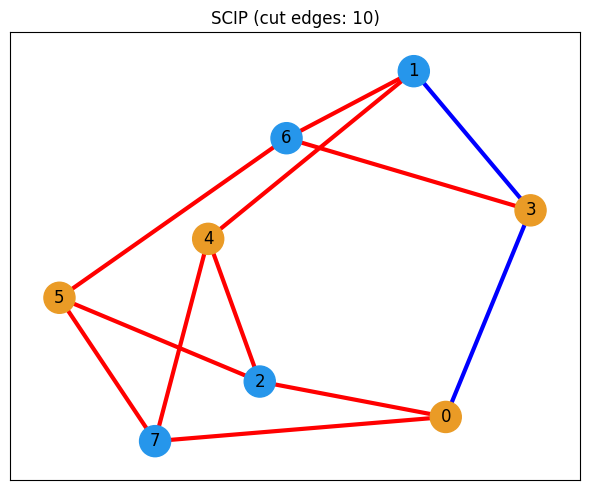

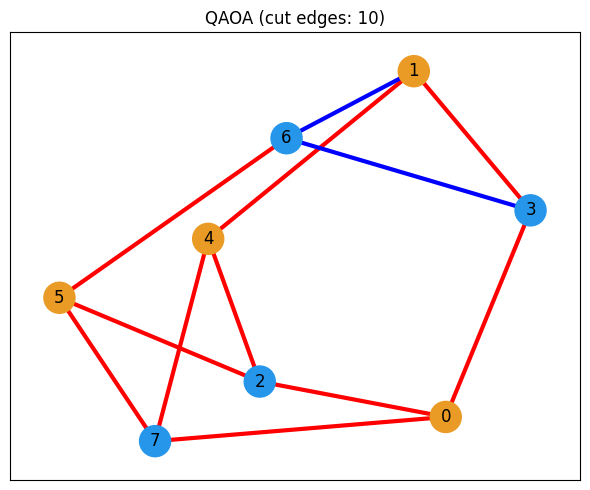

In [12]:
show_solution(scip_assignment, "SCIP")
show_solution(best_spins, "QAOA")

## Summary

- The original eight-node graph and five-layer QAOA are executable.
- One deterministic QPY artifact is rebound throughout continuous COBYLA
  optimization and final 2,000-shot evaluation.
- Energy distribution, best partition, graph visualization, and SCIP
  comparison reproduce the original analysis.
- Switching the same experiment from local Aer to `QBraidDevice` changes only
  the endpoint and compiles for its target; remote submission remains explicit.